# Flower image classification: end-to-end ML pipeline

**Task.** Classify a photo as one of five flower species (`daisy`, `dandelion`, `roses`, `sunflowers`, `tulips`) or reject it as `not_flower`.
**Data type.** Images (unstructured, non-tabular).
**Approach.** Transfer learning: a frozen MobileNetV2 (pre-trained on ImageNet) turns each photo into a 1280-number embedding, and a regularised logistic regression is trained on top.
This is cheap to *retrain* inside a running service, which is the point of the project's MLOps part.

Notebook outline: 1 data acquisition, 2 exploration and visualisation (with interpretations), 3 preprocessing, 4 model creation and training, 5 evaluation, 6 prediction function, 7 saving the model.
The same code lives in `src/` and is reused by the API and the UI, so what is shown here is exactly what runs in production.

In [1]:
import sys, warnings, logging, os
from pathlib import Path
warnings.filterwarnings("ignore")
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
sys.path.insert(0, str(Path.cwd().parent))   # repo root, so `import src` works

import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from PIL import Image
sns.set_theme(style="whitegrid", context="notebook")

from src import preprocessing as pp
from src import model as mdl
from src.prediction import predict_image

## 1. Data acquisition

The public *TensorFlow flowers* dataset (3,670 photos, 5 species) plus a small hand-collected `not_flower` class (people, animals and everyday objects) so the model can learn to reject non-flowers. `python train.py --prepare` does the same thing as the cell below.

In [2]:
if not pp.list_images(pp.TRAIN_DIR):
    if not pp.RAW_DIR.exists():
        pp.download_dataset()
    pp.prepare_dataset()          # stratified 80/20 split, seed=42

stats = pd.DataFrame(pp.dataset_stats()).fillna(0).astype(int)
stats["total"] = stats.sum(axis=1)
stats.loc["TOTAL"] = stats.sum()
stats

,train,test,total
daisy,507,126,633
dandelion,718,180,898
not_flower,19,5,24
roses,513,128,641
sunflowers,559,140,699
tulips,639,160,799
TOTAL,2955,739,3694


## 2. Exploration and visualisation

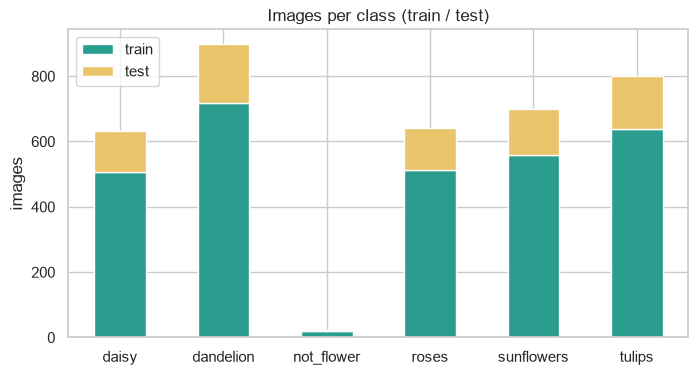

In [3]:
fig, ax = plt.subplots(figsize=(8, 4))
stats.drop("TOTAL")[["train", "test"]].plot.bar(stacked=True, ax=ax, color=["#2a9d8f", "#e9c46a"])
ax.set_title("Images per class (train / test)"); ax.set_ylabel("images"); plt.xticks(rotation=0)
plt.show()

**Class balance.** The five flower classes hold 500-900 training images each, but `not_flower` has only ~19. The classifier will see this class about 40x less often than a flower class, so its recall will be fragile (we use `class_weight='balanced'` to compensate and later show the effect). This is why the app lets users upload more `not_flower` examples and retrain.

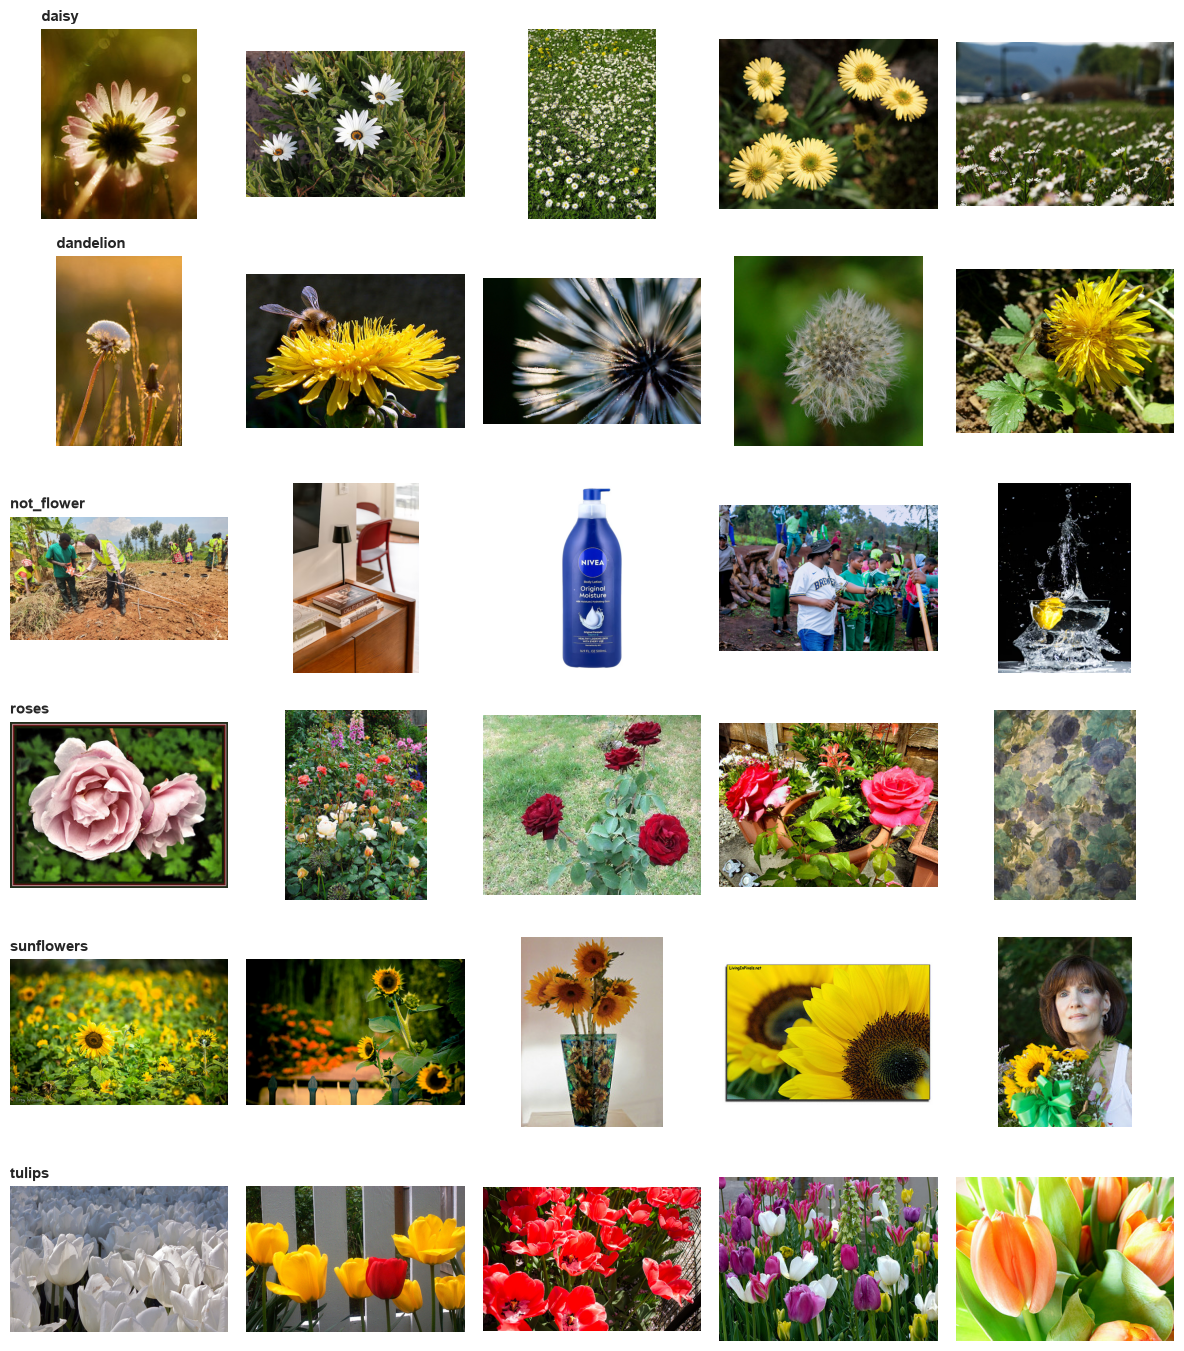

In [4]:
classes = sorted(pp.dataset_stats()["train"])
fig, axes = plt.subplots(len(classes), 5, figsize=(12, 2.3 * len(classes)))
rng = np.random.default_rng(1)
for row, label in enumerate(classes):
    files = [p for p, l in pp.list_images(pp.TRAIN_DIR) if l == label]
    for col, path in enumerate(rng.choice(files, 5, replace=False)):
        axes[row, col].imshow(Image.open(path).convert("RGB")); axes[row, col].axis("off")
    axes[row, 0].set_title(label, loc="left", fontsize=11, fontweight="bold")
plt.tight_layout(); plt.show()

In [5]:
df = pd.DataFrame(pp.image_statistics(per_class=200))
order = classes
df.groupby("label").agg(["mean", "std"]).round(1).T

label               daisy  dandelion  not_flower  roses  sunflowers  tulips
width        mean   360.7      360.4       831.3  368.9       362.7   369.5
             std    114.4      113.6       701.8  114.1       113.0   125.0
height       mean   274.2      271.6       797.4  273.9       270.3   268.8
             std     56.0       52.3       633.9   49.0        50.8    53.1
aspect_ratio mean     1.3        1.3         1.1    1.3         1.3     1.4
             std      0.3        0.3         0.5    0.3         0.3     0.4
brightness   mean   106.0       98.2       135.0  103.7       104.3   101.1
             std     35.1       32.9        61.1   39.3        23.8    32.0
red          mean   113.0      109.0       137.6  130.0       125.6   122.0
             std     38.0       37.0        60.4   45.1        29.9    36.1
green        mean   112.7      110.4       135.8   97.4       119.9   101.4
             std     35.5       33.1        61.2   42.3        27.1    34.8
blue         mean    92.2       75.3       131.6   83.7        67.3    79.9
             std     39.0       42.8        67.5   44.5        38.5    37.5
sharpness    mean  1142.4      614.5       692.9  931.0       980.5  1024.9
             std    676.5      406.3       540.5  590.4       530.3   596.7

### Feature 1: image resolution (width x height)

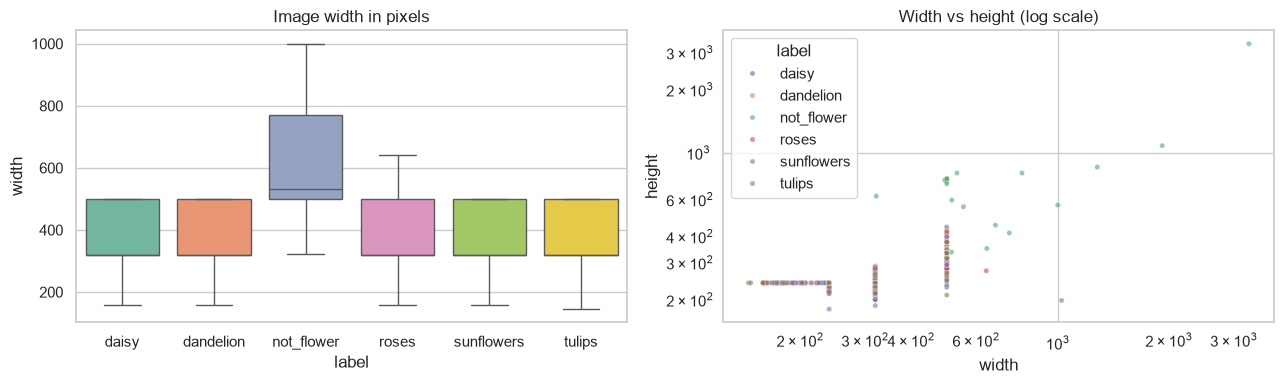

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.boxplot(data=df, x="label", y="width", order=order, ax=axes[0], showfliers=False, palette="Set2")
axes[0].set_title("Image width in pixels")
sns.scatterplot(data=df, x="width", y="height", hue="label", hue_order=order, ax=axes[1], s=14, alpha=.6)
axes[1].set_xscale("log"); axes[1].set_yscale("log"); axes[1].set_title("Width vs height (log scale)")
plt.tight_layout(); plt.show()

**Story.** Every flower photo is ~360 x 270 px (the dataset was scraped and normalised by one source), whereas `not_flower` photos average ~830 x 800 px and are far more variable, because they came from phones, stock sites and screenshots.
This is a **dataset-bias warning**: image size would be a "shortcut" for telling the classes apart. Our pipeline removes this shortcut because every image is resized to 160 x 160 before feature extraction, so resolution never reaches the model. It also tells us that real user photos (large, phone-made) are *out of distribution* relative to the flower training images.

### Feature 2: colour channel means (red / green / blue)

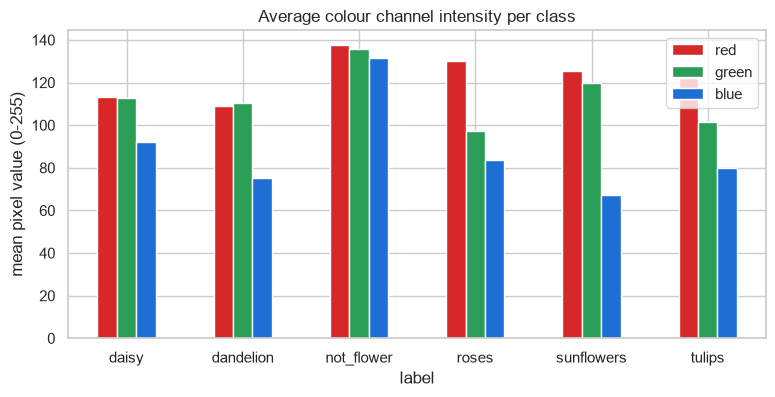

In [7]:
colour = df.groupby("label")[["red", "green", "blue"]].mean().loc[order]
colour.plot.bar(color=["#d62828", "#2a9d57", "#1d6fd6"], figsize=(9, 4))
plt.title("Average colour channel intensity per class"); plt.ylabel("mean pixel value (0-255)"); plt.xticks(rotation=0)
plt.show()

**Story.** Colour carries real botanical signal. **Sunflowers** have the lowest blue (~67) with high red and green, which is the yellow of their petals. **Dandelions** are also blue-poor (~75) but greener (leaves and grass). **Roses** are the only class where red clearly exceeds green (130 vs 97), which matches their red and pink petals. **Daisies** have the highest blue (~92) because white petals reflect all channels.
Expect confusions between classes whose colours overlap (rose vs tulip, both red/pink), which the confusion matrix later confirms.

### Feature 3: brightness and sharpness (texture detail)

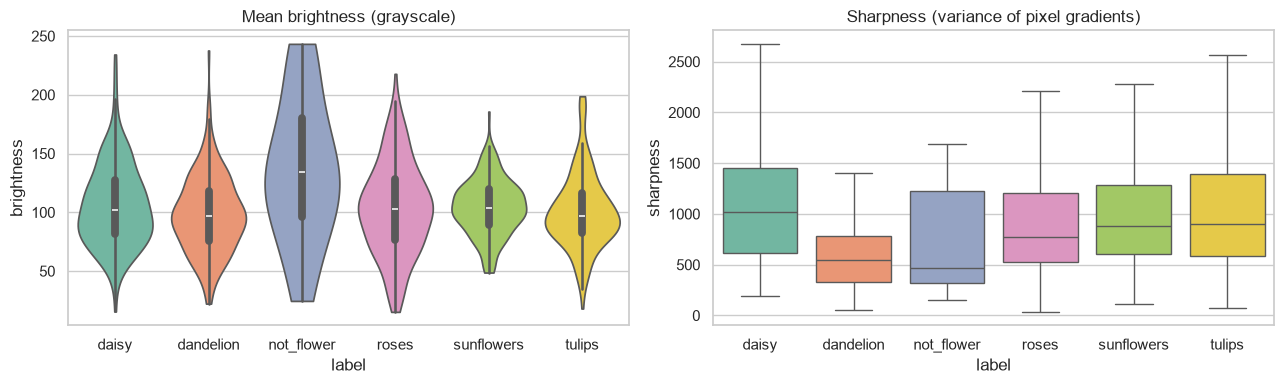

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.violinplot(data=df, x="label", y="brightness", order=order, ax=axes[0], palette="Set2", cut=0)
axes[0].set_title("Mean brightness (grayscale)")
sns.boxplot(data=df, x="label", y="sharpness", order=order, ax=axes[1], showfliers=False, palette="Set2")
axes[1].set_title("Sharpness (variance of pixel gradients)")
plt.tight_layout(); plt.show()

**Story.** `not_flower` photos are the brightest (~135 vs ~100) and have the widest brightness spread (std 61 vs 24-39), reflecting many different scenes (indoor products, portraits, screenshots) versus outdoor garden shots.
**Daisies** are the sharpest class (~1140, nearly double the dandelion's ~615): small, high-contrast white petals on dark green produce many edges, while dandelion's soft yellow pompoms and out-of-focus backgrounds produce few.
Sharpness is thus a texture cue a CNN can exploit, and low-sharpness/low-contrast photos are likely where the model is least certain.

## 3. Preprocessing

Steps applied identically at training time and at prediction time (`src/preprocessing.py`):
1. decode and validate (reject corrupt files, >16 MP images or >20 MB files)
2. convert to RGB (drops alpha/palette modes)
3. resize to 160 x 160
4. scale to the range MobileNetV2 expects ([-1, 1])
5. pass through the frozen MobileNetV2 and average-pool to a 1280-d embedding

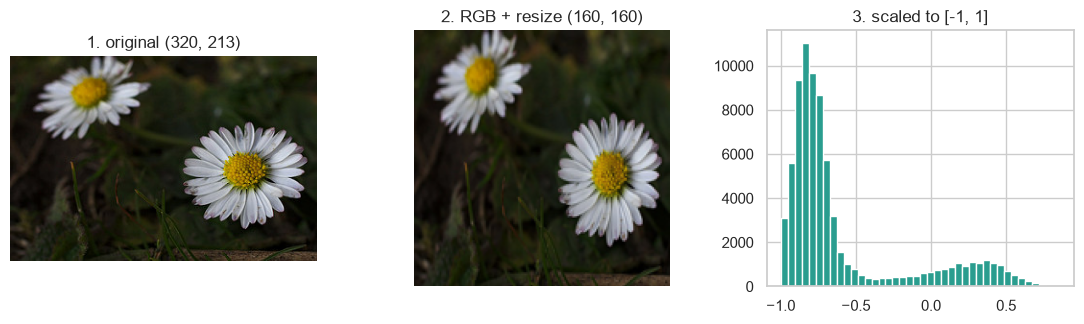

embedding shape: (1, 1280) | first 5 values: [0.145 0.    0.    0.    0.   ]


In [9]:
path, label = pp.list_images(pp.TRAIN_DIR)[100]
raw = Image.open(path)
arr = pp.read_image(path)
fig, axes = plt.subplots(1, 3, figsize=(11, 3.4))
axes[0].imshow(raw); axes[0].set_title(f"1. original {raw.size}")
axes[1].imshow(arr); axes[1].set_title(f"2. RGB + resize {arr.shape[:2]}")
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
scaled = preprocess_input(arr.astype("float32"))
axes[2].hist(scaled.ravel(), bins=40, color="#2a9d8f"); axes[2].set_title("3. scaled to [-1, 1]")
for a in axes[:2]: a.axis("off")
plt.tight_layout(); plt.show()
emb = pp.image_features(path)
print("embedding shape:", emb.shape, "| first 5 values:", emb[0, :5].round(3))

3691 embeddings in the feature store (0 newly computed)
train: (2952, 1280) test: (739, 1280)


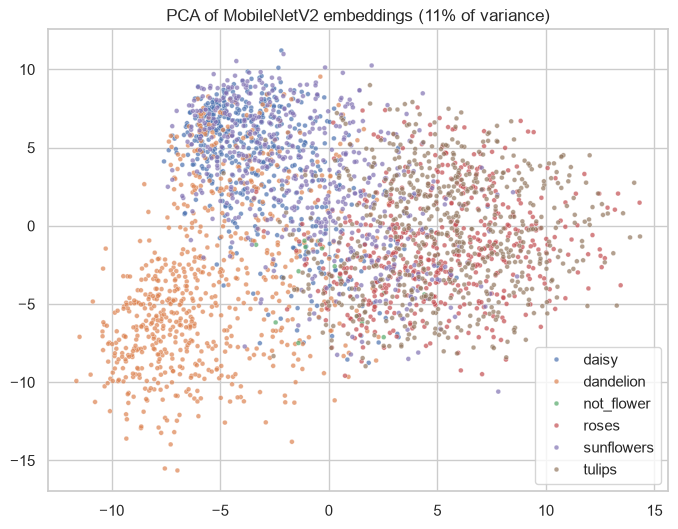

In [10]:
store = pp.FeatureStore()
n_new = store.sync()
print(f"{len(store.labels)} embeddings in the feature store ({n_new} newly computed)")
x_train, y_train = store.split("train")
x_test, y_test = store.split("test")
print("train:", x_train.shape, "test:", x_test.shape)

from sklearn.decomposition import PCA
pca = PCA(2, random_state=0).fit(x_train)
z = pca.transform(x_train)
fig, ax = plt.subplots(figsize=(8, 6))
sns.scatterplot(x=z[:, 0], y=z[:, 1], hue=y_train, hue_order=order, s=12, alpha=.7, ax=ax)
ax.set_title(f"PCA of MobileNetV2 embeddings ({pca.explained_variance_ratio_.sum():.0%} of variance)")
plt.show()

**Reading the embedding map.** Two principal components capture only part of the variance, so classes overlap in this view, but the species still form visibly different regions. The `not_flower` points are few and scattered, which foreshadows the evaluation results for that class.

## 4. Model creation and training

In [11]:
from sklearn.dummy import DummyClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, f1_score
import time

candidates = {
    "Majority-class baseline": DummyClassifier(strategy="most_frequent"),
    "kNN (k=5)": KNeighborsClassifier(5),
    "SVM (RBF)": SVC(class_weight="balanced"),
    "Logistic regression (chosen)": mdl.build_estimator(),
}
rows = []
for name, est in candidates.items():
    t = time.perf_counter(); est.fit(x_train, y_train); dt = time.perf_counter() - t
    p = est.predict(x_test)
    rows.append({"model": name, "test accuracy": accuracy_score(y_test, p),
                 "macro F1": f1_score(y_test, p, average="macro"), "fit seconds": dt})
pd.DataFrame(rows).round(3).set_index("model")

,test accuracy,macro F1,fit seconds
model,,,
Majority-class baseline,0.244,0.065,0.000
kNN (k=5),0.840,0.698,0.002
SVM (RBF),0.882,0.737,1.602
Logistic regression (chosen),0.888,0.778,0.159


The majority-class baseline shows what 'no learning' scores. Logistic regression is chosen: it matches or beats the alternatives, gives calibrated class probabilities for confidence reporting, and fits in seconds, which keeps the retrain button responsive.

In [12]:
artifact, metrics = mdl.train_model(store)
print(f"fit time: {metrics['fit_seconds']}s | train accuracy {metrics['train_accuracy']:.3f} | test accuracy {metrics['accuracy']:.3f}")

fit time: 0.12s | train accuracy 1.000 | test accuracy 0.888


The gap between train and test accuracy shows how much the model over-fits; a small gap means the linear head generalises.

## 5. Evaluation on the held-out test set

In [13]:
summary = pd.Series({k: metrics[k] for k in
    ["accuracy", "macro_precision", "macro_recall", "macro_f1", "weighted_f1", "roc_auc_ovr", "log_loss"]})
display(summary.round(4).to_frame("test set"))
display(pd.DataFrame(metrics["per_class"]).T.round(3))

,test set
accuracy,0.8877
macro_precision,0.7833
macro_recall,0.7744
macro_f1,0.7783
weighted_f1,0.8872
roc_auc_ovr,0.9822
log_loss,0.5341


,precision,recall,f1-score,support
daisy,0.925,0.881,0.902,126.000
dandelion,0.929,0.939,0.934,180.000
not_flower,0.250,0.200,0.222,5.000
roses,0.844,0.844,0.844,128.000
sunflowers,0.889,0.914,0.901,140.000
tulips,0.863,0.869,0.866,160.000
accuracy,0.888,0.888,0.888,0.888
macro avg,0.783,0.774,0.778,739.000
weighted avg,0.887,0.888,0.887,739.000


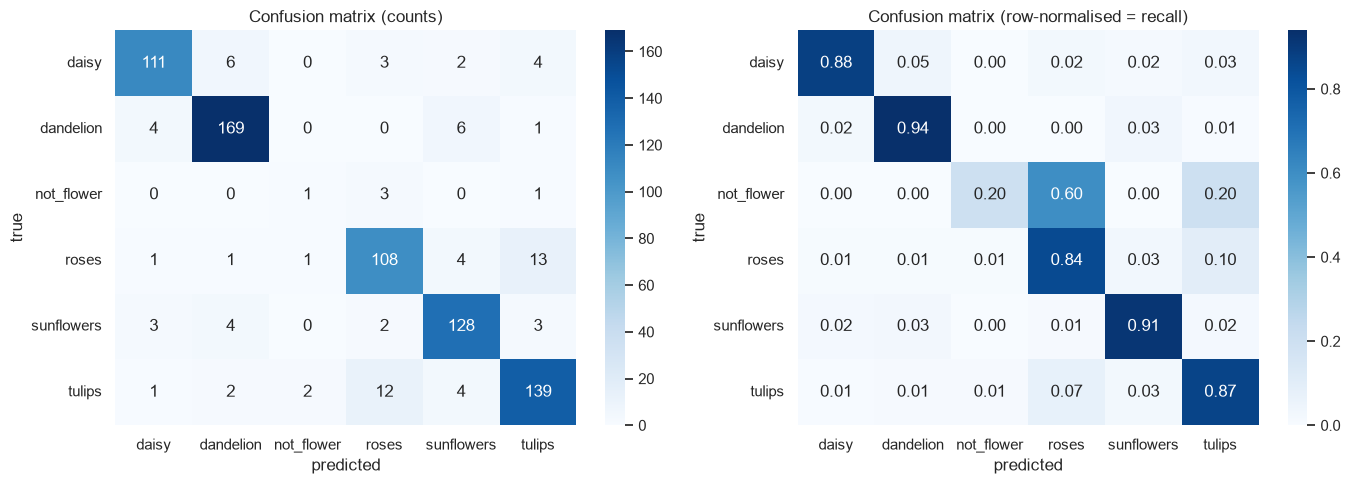

In [14]:
from sklearn.metrics import confusion_matrix
est = artifact["estimator"]; pred = est.predict(x_test); cls = list(est.classes_)
cm = confusion_matrix(y_test, pred, labels=cls)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=cls, yticklabels=cls, ax=axes[0])
axes[0].set_title("Confusion matrix (counts)")
sns.heatmap(cm / cm.sum(1, keepdims=True), annot=True, fmt=".2f", cmap="Blues", xticklabels=cls, yticklabels=cls, ax=axes[1])
axes[1].set_title("Confusion matrix (row-normalised = recall)")
for a in axes: a.set_xlabel("predicted"); a.set_ylabel("true")
plt.tight_layout(); plt.show()

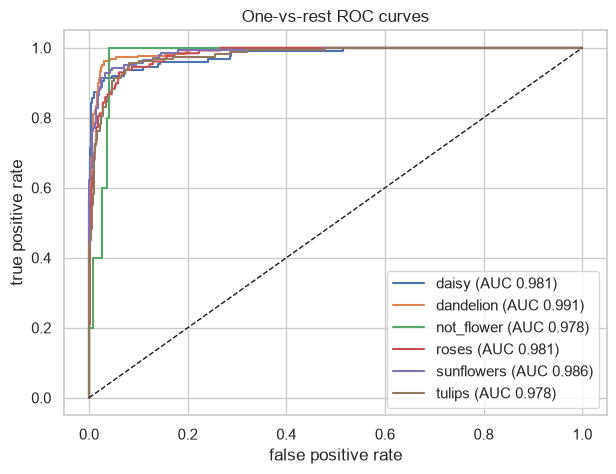

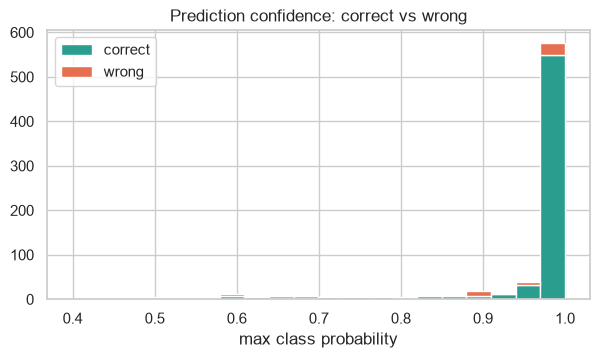

In [15]:
from sklearn.metrics import roc_curve, auc
from sklearn.preprocessing import label_binarize
proba = est.predict_proba(x_test); Y = label_binarize(y_test, classes=cls)
fig, ax = plt.subplots(figsize=(7, 5))
for i, c in enumerate(cls):
    fpr, tpr, _ = roc_curve(Y[:, i], proba[:, i]); ax.plot(fpr, tpr, label=f"{c} (AUC {auc(fpr, tpr):.3f})")
ax.plot([0, 1], [0, 1], "k--", lw=1); ax.set_xlabel("false positive rate"); ax.set_ylabel("true positive rate")
ax.set_title("One-vs-rest ROC curves"); ax.legend(); plt.show()

conf = proba.max(1); correct = pred == y_test
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.hist([conf[correct], conf[~correct]], bins=20, stacked=True, label=["correct", "wrong"], color=["#2a9d8f", "#e76f51"])
ax.set_title("Prediction confidence: correct vs wrong"); ax.set_xlabel("max class probability"); ax.legend(); plt.show()

### Interpretation

* **Overall:** accuracy is ~89% and the ROC curves sit well above the diagonal (macro AUC ~0.98), so the embeddings separate the species well.
* **Flowers:** per-class F1 is 0.84-0.93 for all five species (dandelion best at 0.93, roses weakest at 0.84). The largest confusion is **roses vs tulips** (13 tulips predicted as rose, 12 roses as tulip in the matrix), which share red/pink colouring (see the colour-channel chart).
* **`not_flower` is the weak spot:** its test set contains only 5 images, so its precision/recall (0.25 / 0.20, F1 0.22) are both poor and noisy, and drag *macro* precision/recall/F1 (~0.78) well below the accuracy (~0.89). Accuracy alone would hide this because the class is ~0.7% of the data, which is why we report macro metrics and the confusion matrix.
* **Confidence is partly informative:** wrong predictions have lower mean confidence (~0.83) than correct ones (~0.97), so a confidence threshold could route doubtful photos to human review, but some mistakes are still made confidently.
* **Next step the pipeline supports:** upload more varied `not_flower` photos in the UI and press *Retrain*; this notebook's metrics improve when that class grows.

## 6. Prediction function

`predict_image(bytes)` is what the API calls: it validates the file, embeds it and returns the label, confidence and top-3 probabilities.

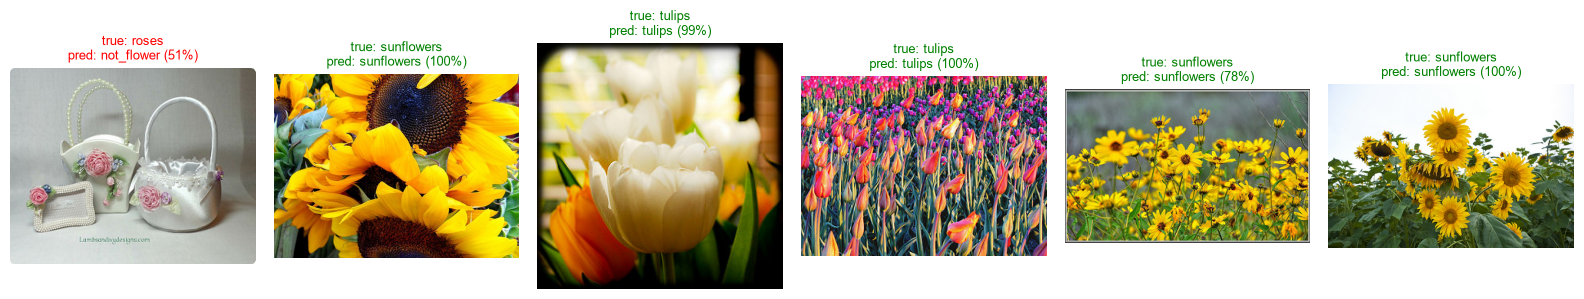

{'label': 'sunflowers', 'confidence': 0.9999988079071045, 'is_flower': True, 'top': [('sunflowers', 0.9999988079071045), ('dandelion', 1.10321218471654e-06), ('not_flower', 7.380805300272186e-08)]}


In [16]:
test_items = pp.list_images(pp.TEST_DIR)
rng = np.random.default_rng(7)
picks = [test_items[i] for i in rng.choice(len(test_items), 6, replace=False)]
fig, axes = plt.subplots(1, 6, figsize=(16, 3.2))
for ax, (path, truth) in zip(axes, picks):
    r = predict_image(path.read_bytes(), artifact)
    ax.imshow(Image.open(path).convert("RGB")); ax.axis("off")
    ax.set_title(f"true: {truth}\npred: {r['label']} ({r['confidence']:.0%})",
                 fontsize=9, color="green" if r["label"] == truth else "red")
plt.tight_layout(); plt.show()
print(r)

## 7. Save the model

The artifact is a pickle (`.pkl`) holding the fitted scikit-learn pipeline plus metadata. The MobileNetV2 backbone is not stored: Keras downloads the ImageNet weights on first use.

In [17]:
mdl.save_model(artifact)                       # models/flower_classifier.pkl
reloaded = mdl.load_model()
sample_path = picks[0][0]
a = predict_image(sample_path.read_bytes(), artifact); b = predict_image(sample_path.read_bytes(), reloaded)
assert a["label"] == b["label"] and abs(a["confidence"] - b["confidence"]) < 1e-9
print("Saved to", mdl.MODEL_PATH, f"({mdl.MODEL_PATH.stat().st_size / 1024:.0f} KB); reload check passed")

Saved to /Users/MAC/Documents/projects/ALU/Machine_Learning_Pipeline/Summative_Machine_Learning_Pipeline_Module/models/flower_classifier.pkl (62 KB); reload check passed
